# Week 9 — Neural Networks with the Molecular Properties Dataset

## Project context

Research question: **What factors affect the lipophilicity (LogP) of chemical compounds? Could machine learning use this information to forecast bioactivity?**

This notebook adapts the Week 9 neural-network lesson to `properties.csv`.

**Prediction task:** classify each compound as lower-LogP or higher-LogP using the median Mannhold LogP as the threshold. This is a supervised classification exercise. The dataset does **not** contain measured bioactivity labels, so this notebook does not predict bioactivity.

We use the same six molecular descriptors used in the earlier classification work. Mannhold LogP is the target and is not included among the input features. XLogP is also excluded because it is another LogP estimate.

## 1. Load and inspect the dataset

Update the path only if your `properties.csv` is stored somewhere else. The raw-string prefix `r` is important for Windows paths.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print(df.dtypes)

Dataset shape: (15166, 34)


,index,row ID,Molecule,Molecule name,Mannhold LogP,Atomic Polarizabilities,Aromatic Atoms Count,Aromatic Bonds Count,Element Count,Bond Polarizabilities,...,XLogP,Zagreb Index,Molecular Formula,Formal Charge,Formal Charge (pos),Formal Charge (neg),Heavy Atoms Count,Molar Mass,SP3 Character,Rotatable Bonds Count (non terminal)
0,0,Row0,N,H3N,1.35,3.100379,0,0,4,1.299621,...,0.000,0,H3N,0,0,0,1,17.030525,0.000000,0
1,1,Row1,O=C(O)c1c(OC(=O)C)cccc1,C9H8O4,2.01,24.382344,6,6,21,12.577656,...,1.422,60,C9H8O4,0,0,0,13,180.157769,0.047619,3
2,2,Row2,C#C,C2H2,1.68,4.853586,0,0,4,2.186414,...,0.418,2,C2H2,0,0,0,2,26.037353,0.000000,0
3,3,Row3,P(=O)(OP(=O)(OC[C@H]1O[C@@H](n2c3ncnc(c3nc2)N)...,C10H16N5O13P3,0.25,55.084688,9,10,47,55.749312,...,-5.533,170,C10H16N5O13P3,0,0,0,31,507.181476,0.106383,8
4,4,Row4,S1C([C@H](C(=O)O)N2[C@H]1[C@H](NC(=O)[C@H](N)c...,C16H19N3O4S,2.34,50.237067,6,6,43,27.904933,...,-1.732,132,C16H19N3O4S,0,0,0,24,349.406463,0.162791,4


index                                       int64
row ID                                     object
Molecule                                   object
Molecule name                              object
Mannhold LogP                             float64
Atomic Polarizabilities                    object
Aromatic Atoms Count                        int64
Aromatic Bonds Count                        int64
Element Count                               int64
Bond Polarizabilities                      object
Bond Count                                  int64
Eccentric Connectivity Index              float64
Fragment Complexity                       float64
VABC Volume Descriptor                     object
Hydrogen Bond Acceptors                     int64
Hydrogen Bond Donors                        int64
Largest Chain                               int64
Largest Pi Chain                            int64
Petitjean Number                          float64
Rotatable Bonds Count                       int64


## 2. Prepare features and target

Some descriptor columns may contain text such as `#NUM!`. Convert the selected feature columns to numeric values; invalid entries become missing values and will be imputed inside the model pipeline.

The target is:
- `0` = lower LogP (below the dataset median)
- `1` = higher LogP (at or above the dataset median)

The six predictors are molecular descriptors. The target column is not used as an input feature.

In [2]:
target_column = "Mannhold LogP"

feature_names = ['Molecular Weight', 'Topological Polar Surface Area', 'Hydrogen Bond Acceptors', 'Hydrogen Bond Donors', 'Rotatable Bonds Count', 'SP3 Character']

# Convert descriptor columns to numeric; invalid strings become NaN.
X = df[feature_names].apply(pd.to_numeric, errors="coerce")
logp = pd.to_numeric(df[target_column], errors="coerce")

# Keep rows with a known target value.
valid_target = logp.notna()
X = X.loc[valid_target].copy()
logp = logp.loc[valid_target].copy()

logp_median = logp.median()
y = (logp >= logp_median).astype(int)

print(f"Rows used: {len(X):,}")
print(f"Mannhold LogP median: {logp_median:.3f}")
print("\\nClass counts:")
print(y.value_counts().sort_index().rename(index={0: "Lower LogP", 1: "Higher LogP"}))
print("\\nMissing values in input features:")
display(X.isna().sum().to_frame("Missing values"))

Rows used: 15,166
Mannhold LogP median: 2.450
\nClass counts:
Mannhold LogP
Lower LogP     7269
Higher LogP    7897
Name: count, dtype: int64
\nMissing values in input features:


,Missing values
Molecular Weight,3
Topological Polar Surface Area,7
Hydrogen Bond Acceptors,0
Hydrogen Bond Donors,0
Rotatable Bonds Count,0
SP3 Character,0


## 3. Split the data

Use a stratified 60/20/20 split for training, validation and testing. The test set is held back until the final evaluation.

Preprocessing (median imputation and standardisation) is placed inside each pipeline. This means the imputer and scaler are fitted on training data only.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    random_state=42, stratify=y_trainval
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Training rows: 9099
Validation rows: 3033
Test rows: 3034


## 4. Establish a baseline: Logistic Regression

Logistic Regression is included as a baseline so we can compare the neural network with a simpler model using the same split and features.

Logistic Regression validation results
Accuracy: 0.851
Precision: 0.859
Recall: 0.855
F1: 0.857
              precision    recall  f1-score   support

           0       0.84      0.85      0.85      1454
           1       0.86      0.85      0.86      1579

    accuracy                           0.85      3033
   macro avg       0.85      0.85      0.85      3033
weighted avg       0.85      0.85      0.85      3033



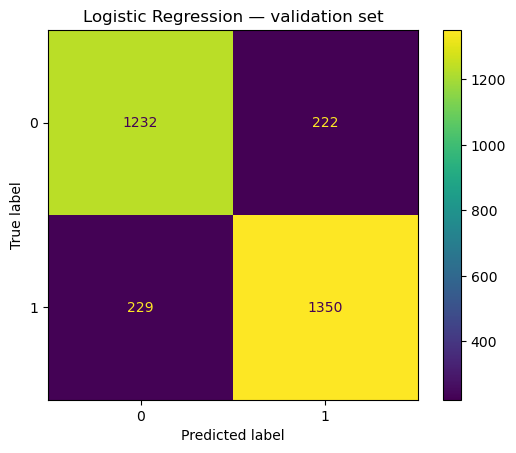

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_train, y_train)
logistic_val_predictions = logistic_model.predict(X_val)

print("Logistic Regression validation results")
print("Accuracy:", round(accuracy_score(y_val, logistic_val_predictions), 3))
print("Precision:", round(precision_score(y_val, logistic_val_predictions), 3))
print("Recall:", round(recall_score(y_val, logistic_val_predictions), 3))
print("F1:", round(f1_score(y_val, logistic_val_predictions), 3))
print(classification_report(y_val, logistic_val_predictions))
ConfusionMatrixDisplay.from_predictions(y_val, logistic_val_predictions)
plt.title("Logistic Regression — validation set")
plt.show()

## 5. Train a Multilayer Perceptron (MLP)

An MLP is a feed-forward neural network. Hidden layers allow it to learn non-linear patterns in the input features.

The network below has two hidden layers (32 and 16 neurons) and uses ReLU activation. Early stopping monitors an internal validation portion of the training data and stops training when performance stops improving.

MLP validation results
Accuracy: 0.886
Precision: 0.879
Recall: 0.906
F1: 0.892
              precision    recall  f1-score   support

           0       0.89      0.86      0.88      1454
           1       0.88      0.91      0.89      1579

    accuracy                           0.89      3033
   macro avg       0.89      0.89      0.89      3033
weighted avg       0.89      0.89      0.89      3033

Training iterations: 46
Best internal validation score: 0.903


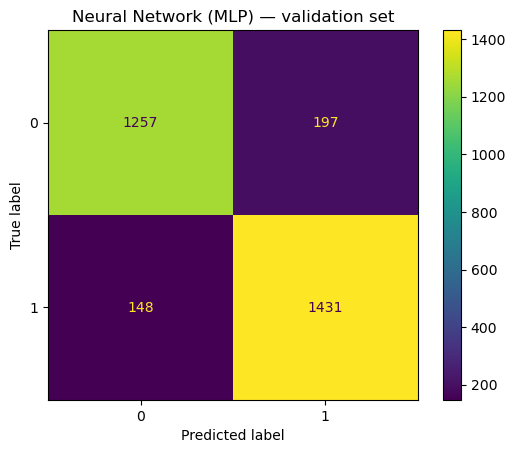

In [5]:
from sklearn.neural_network import MLPClassifier

neural_network = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.001,
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=20,
        random_state=42
    ))
])

neural_network.fit(X_train, y_train)
mlp_val_predictions = neural_network.predict(X_val)

print("MLP validation results")
print("Accuracy:", round(accuracy_score(y_val, mlp_val_predictions), 3))
print("Precision:", round(precision_score(y_val, mlp_val_predictions), 3))
print("Recall:", round(recall_score(y_val, mlp_val_predictions), 3))
print("F1:", round(f1_score(y_val, mlp_val_predictions), 3))
print(classification_report(y_val, mlp_val_predictions))

mlp_fitted = neural_network.named_steps["model"]
print("Training iterations:", mlp_fitted.n_iter_)
print("Best internal validation score:", round(mlp_fitted.best_validation_score_, 3))

ConfusionMatrixDisplay.from_predictions(y_val, mlp_val_predictions)
plt.title("Neural Network (MLP) — validation set")
plt.show()

## 6. Compare the validation results

Compare models on the same validation rows. Accuracy gives the overall proportion correct; precision, recall and F1 provide more detail about performance for the higher-LogP class.

In [6]:
validation_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Neural Network (MLP)"],
    "Accuracy": [
        accuracy_score(y_val, logistic_val_predictions),
        accuracy_score(y_val, mlp_val_predictions)
    ],
    "Precision (higher LogP)": [
        precision_score(y_val, logistic_val_predictions),
        precision_score(y_val, mlp_val_predictions)
    ],
    "Recall (higher LogP)": [
        recall_score(y_val, logistic_val_predictions),
        recall_score(y_val, mlp_val_predictions)
    ],
    "F1 (higher LogP)": [
        f1_score(y_val, logistic_val_predictions),
        f1_score(y_val, mlp_val_predictions)
    ]
})
display(validation_comparison.round(3))

,Model,Accuracy,Precision (higher LogP),Recall (higher LogP),F1 (higher LogP)
0,Logistic Regression,0.851,0.859,0.855,0.857
1,Neural Network (MLP),0.886,0.879,0.906,0.892


## 7. Final evaluation on the held-out test set

Choose the model using the validation results, then evaluate that selected model once on the test set. Change `selected_model` below if your validation comparison favours the other model.

Do not repeatedly adjust the model based on test results: that would make the test set part of model development.

Final held-out test results
Accuracy: 0.885
Precision: 0.87
Recall: 0.915
F1: 0.892
              precision    recall  f1-score   support

           0       0.90      0.85      0.88      1454
           1       0.87      0.92      0.89      1580

    accuracy                           0.88      3034
   macro avg       0.89      0.88      0.88      3034
weighted avg       0.89      0.88      0.88      3034



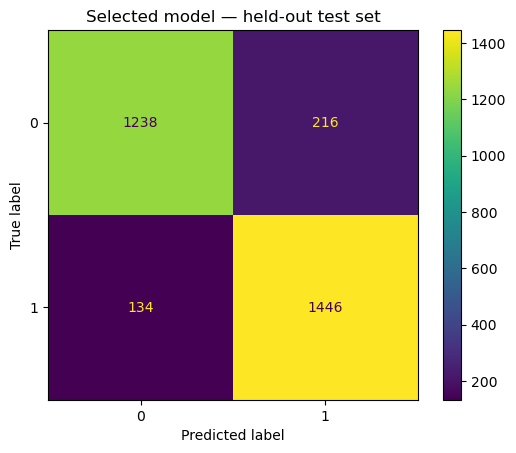

In [7]:
# Select the model based on validation performance.
selected_model = neural_network  # Change to logistic_model if validation results support it.

test_predictions = selected_model.predict(X_test)

print("Final held-out test results")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 3))
print("Precision:", round(precision_score(y_test, test_predictions), 3))
print("Recall:", round(recall_score(y_test, test_predictions), 3))
print("F1:", round(f1_score(y_test, test_predictions), 3))
print(classification_report(y_test, test_predictions))

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions)
plt.title("Selected model — held-out test set")
plt.show()

## 8. Interpretation for the project

Use the outputs above to answer:

1. Did the MLP outperform Logistic Regression on the validation set?
2. Did the result improve across all metrics, or only accuracy?
3. What do false positives and false negatives mean for the lower-/higher-LogP classification?
4. Did early stopping finish before the maximum number of iterations?
5. Does the neural network provide evidence that molecular descriptors contain useful information about LogP?

### Strengths and limitations

**Strengths**
- An MLP can learn non-linear relationships.
- It can combine information from several molecular descriptors.
- The pipeline handles missing feature values and scaling consistently.

**Limitations**
- Neural networks can be harder to interpret than simpler models.
- Results depend on architecture and hyperparameter choices.
- Scaling and imputation do not remove all data-quality issues.
- Good performance on a random test split does not guarantee performance on genuinely new chemical families.
- The target is LogP category, not biological activity. The dataset has no measured bioactivity label.

A neural network is not automatically better than a tree-based model. Compare its results with the Week 8 Random Forest using care, because the split and evaluation setup may differ.

## 9. Optional experiments

Change one setting at a time while keeping the split fixed:

- Try `hidden_layer_sizes=(16,)` or `(64, 32)`.
- Try `activation="tanh"`.
- Increase `alpha` to `0.01` to apply stronger regularisation.
- Compare validation F1 as well as accuracy.

Record each experiment and avoid selecting settings based on the held-out test set.